# Part 2.1 - Kialo collection and exploration
This notebook follows `PART2_PLAN.md`. It uses the official Kialo listing endpoint and official text exports. Automated collection is disabled by default: obtain the required academic permission and set `RUN_COLLECTION = True` only after checking the conditions of use.

Reference implementation: https://github.com/4mbroise/ADC (no licence in the reference repository). Our modifications are the export validation, failure log, parser corrections, citation/link handling, retention of thesis relations, and reproducible controls.

In [1]:
from pathlib import Path
import json
import pandas as pd
from part2_kialo import (discussion_listing, validate_listing, save_listing,
                             download_exports, parse_exports, exploration_summary)

DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
RUN_COLLECTION = False
LIMIT = 250
SEED_DATE = '2026-10-17'

## 1. Discussion listing

In [2]:
if RUN_COLLECTION:
    listing_payload = discussion_listing(limit=LIMIT)
    listing_path = save_listing(listing_payload, DATA_DIR / f'kialo_listing_{SEED_DATE}.json')
    listing_check = validate_listing(listing_payload, expected_limit=LIMIT)
    print(listing_path)
    print(listing_check)
else:
    listing_path = DATA_DIR / f'kialo_listing_{SEED_DATE}.json'
    print('Collection disabled. Expected input:', listing_path)

Collection disabled. Expected input: data/kialo_listing_2026-10-17.json


In [3]:
if listing_path.exists():
    listing_payload = json.loads(listing_path.read_text(encoding='utf-8'))
    listing = listing_payload['discussions']
    print(validate_listing(listing_payload, expected_limit=LIMIT))
    listing_frame = pd.DataFrame(listing)
    display(listing_frame[['id', 'title', 'rank', 'language', 'claimAndThesisCount', 'participantCount', 'viewCount', 'voteCount']].head())
else:
    listing = []
    listing_frame = pd.DataFrame()
    print('No listing JSON found yet.')

{'count': 250, 'expected_count': 250, 'count_ok': True, 'unique_ids': True, 'rank_descending': True, 'languages': Counter({'en': 239, 'es': 4, 'de': 3, 'other': 1, 'sk': 1, 'sv': 1, 'fr': 1})}


,id,title,rank,language,claimAndThesisCount,participantCount,viewCount,voteCount
0,29355,Are Purity Pledges Harmful?,49.0,en,362,99,21461,821
1,10143,Should American Football Be Banned?,48.0,en,402,186,33139,2006
2,30339,Should there be One World State?,47.0,en,785,259,34848,2116
3,31027,Do fair trade products cause more good than harm?,46.0,en,202,31,23472,540
4,64072,Should failing banks receive bailouts from the...,45.0,en,239,15,4911,23


## 2. Official exports and failure log
Each export is checked for existence, non-zero size, and a first line beginning with `Discussion Title:`. The delay is at least 1.5 seconds, as required by the protocol.

In [4]:
# Authentication is intentionally external to this notebook.
# Create an authenticated requests.Session through the official Kialo browser flow,
# then assign it to `authenticated_session` without storing credentials in code.
authenticated_session = None
if RUN_COLLECTION and listing:
    if authenticated_session is None:
        raise RuntimeError('Provide an authenticated Kialo session before downloading exports.')
    export_results = download_exports(listing, DATA_DIR / 'exports', delay_seconds=1.5, session=authenticated_session)
    export_log = pd.DataFrame([result.__dict__ for result in export_results])
    export_log.to_csv(DATA_DIR / 'export_log.csv', index=False)
    display(export_log['ok'].value_counts(dropna=False))
else:
    export_log_path = DATA_DIR / 'export_log.csv'
    print('Use official authenticated exports in data/exports and record failures in', export_log_path)

Use official authenticated exports in data/exports and record failures in data/export_log.csv


## 3. Parsing and pair construction

In [5]:
if listing:
    claims, pairs, failures, parse_stats = parse_exports(listing, DATA_DIR / 'exports')
    claims.to_csv(DATA_DIR / 'kialo_claims.csv', index=False)
    pairs.to_csv(DATA_DIR / 'kialo_pairs.csv', index=False)
    failures.to_csv(DATA_DIR / 'parse_failures.csv', index=False)
    parse_stats.to_csv(DATA_DIR / 'parse_stats.csv', index=False)
    print('claims:', len(claims), 'pairs:', len(pairs), 'failures:', len(failures))
else:
    claims = pd.read_csv(DATA_DIR / 'kialo_claims.csv') if (DATA_DIR / 'kialo_claims.csv').exists() else pd.DataFrame()
    pairs = pd.read_csv(DATA_DIR / 'kialo_pairs.csv') if (DATA_DIR / 'kialo_pairs.csv').exists() else pd.DataFrame()
    print('Load generated CSV files after the export step.')

claims: 94707 pairs: 94199 failures: 0


## 4. Exploration
Interpret every table and figure in the final report. Required checks are debate size, depth and branching, Pro/Con balance by depth and tags, text/citation/link statistics, languages, tags, activity correlations, empty claims, failures, and debates without relations.

In [6]:
if not claims.empty:
    tables = exploration_summary(claims, pairs, listing_frame)
    for name, table in tables.items():
        print('---', name, '---')
        display(table.head(20))
else:
    print('Exploration waits for data/kialo_claims.csv and data/kialo_pairs.csv.')

--- by_discussion ---


,discussion_id,claims,max_depth,mean_depth,mean_chars
0,10068,270,7,3.759259,123.785185
1,10104,431,7,3.651972,112.723898
2,10134,482,8,4.562241,138.582988
3,10143,402,9,4.131841,135.890547
4,10214,392,6,3.734694,145.997449
5,1048,443,13,4.347630,161.828442
6,11280,51,4,1.921569,130.745098
7,12218,35,3,1.885714,154.657143
8,1229,2676,13,4.876682,185.933483
9,12545,272,7,3.474265,124.977941


--- by_depth ---


,depth,stance,count
0,0,question,18
1,0,thesis,232
2,1,con,857
3,1,pro,848
4,1,thesis,258
5,2,con,4044
6,2,pro,4460
7,3,con,9188
8,3,pro,9693
9,4,con,12127


--- labels ---


,label,proportion
0,attack,0.505759
1,support,0.494241


... (8 outputs left out)

--- activity_spearman ---


,index,claims,participantCount,viewCount,voteCount
0,claims,1.000000,0.760376,0.869262,0.802197
1,participantCount,0.760376,1.000000,0.927546,0.923259
2,viewCount,0.869262,0.927546,1.000000,0.903934
3,voteCount,0.802197,0.923259,0.903934,1.000000


--- api_count_check ---


,discussion_id,claims,max_depth,mean_depth,mean_chars,claimAndThesisCount,delta
0,10068,270,7,3.759259,123.785185,270,0
1,10104,431,7,3.651972,112.723898,431,0
2,10134,482,8,4.562241,138.582988,482,0
3,10143,402,9,4.131841,135.890547,402,0
4,10214,392,6,3.734694,145.997449,392,0
5,1048,443,13,4.347630,161.828442,443,0
6,11280,51,4,1.921569,130.745098,51,0
7,12218,35,3,1.885714,154.657143,35,0
8,1229,2676,13,4.876682,185.933483,2676,0
9,12545,272,7,3.474265,124.977941,272,0


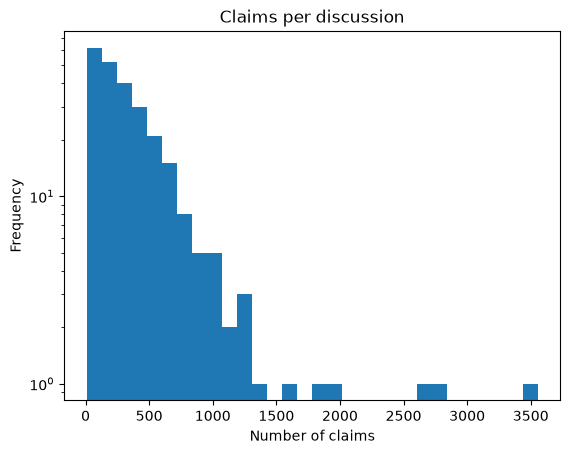

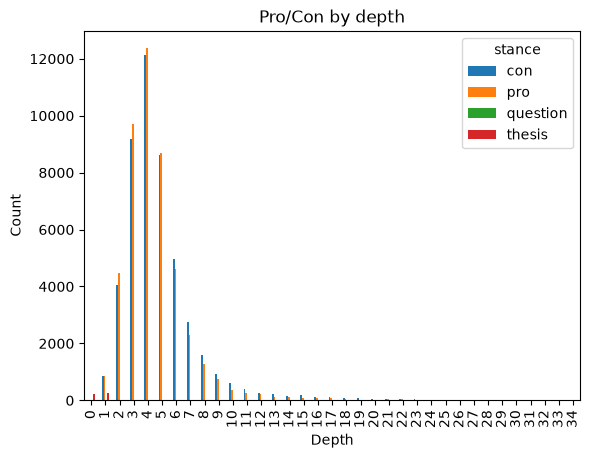

In [7]:
if not claims.empty:
    import matplotlib.pyplot as plt
    claims.groupby('discussion_id').size().plot.hist(bins=30, log=True, title='Claims per discussion')
    plt.xlabel('Number of claims')
    plt.show()
    claims.groupby(['depth', 'stance']).size().unstack(fill_value=0).plot.bar(title='Pro/Con by depth')
    plt.xlabel('Depth')
    plt.ylabel('Count')
    plt.show()